In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

In [23]:
plt.style.use('ggplot')

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report , confusion_matrix , accuracy_score


In [24]:
# Loading the Data

df = pd.read_csv(r"C:\Users\Sushant\Desktop\Deeplearning\portfolio\beehive-audio-health-monitor\data\processed\hive_features.csv")
display(df.head())

,0,1,2,3,4,5,6,7,8,9,...,31,32,33,34,35,36,37,38,39,labels
0,-427.50677,129.64188,11.979298,40.509335,1.207169,13.050173,-0.194375,10.216500,-2.574944,0.418123,...,-0.257239,1.325739,-3.312413,-1.241775,3.203849,-1.312670,-1.431431,-1.245510,-1.242856,1
1,-423.47354,130.63994,9.598702,42.280170,0.206410,13.302734,-0.176522,8.509547,-1.315183,0.039126,...,-0.335081,1.210230,-3.396040,-1.437799,2.648111,-0.589702,-1.815451,-1.555274,-1.144323,1
2,-420.43830,129.54765,8.815701,41.392757,-0.204686,12.852654,0.106757,9.096709,-1.529872,0.482476,...,-0.859225,0.841696,-3.228446,-1.564501,1.822277,-1.054036,-1.281753,-1.363801,-1.009411,1
3,-413.32986,126.28315,7.678269,40.252520,0.451095,15.082141,-1.201098,9.319241,-3.092541,2.933458,...,-1.316527,1.048240,-3.782826,-1.591558,2.223515,-0.955181,-1.406608,-1.547845,-0.844257,1
4,-411.89758,124.87149,7.805428,41.582226,-0.781968,14.662738,0.535498,9.383885,-2.292892,1.478825,...,-1.093424,0.861784,-3.402088,-1.898821,1.770649,-1.163114,-1.327027,-1.713103,-0.761045,1


In [25]:
print(df.shape)

(6000, 41)


In [26]:
# saperating features and the train_test_split
X = df.drop('labels', axis=1)
print(X.shape)

y = df['labels']
print(y.shape)

(6000, 40)
(6000,)


In [27]:
X_train , X_test , y_train , y_test = train_test_split(X,y,
                                                       test_size = 0.2,
                                                       random_state=42 ,
                                                       stratify=y)
print(f'Shape of the X-train {X_train.shape}')
print(f'Shape of the x-test {X_test.shape}')

Shape of the X-train (4800, 40)
Shape of the x-test (1200, 40)


In [33]:
# traiing the Random Forest model
n_estimators = 100
max_depth = 5

model = RandomForestClassifier(n_estimators=n_estimators,
                               max_depth = max_depth,
                               max_features = "sqrt",
                               n_jobs = -1,
                               random_state=42)
model

,n_estimators,100
,criterion,'gini'
,max_depth,5
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [34]:
model.fit(X_train,y_train)

print("Model training complete")

Model training complete


###Evaluating the Model perf

In [35]:
ypred = model.predict(X_test)

print(f'Accuracy score {accuracy_score(y_test , ypred)}')
print(f'Classification Report')

print(classification_report(y_test , ypred , target_names=['Queen bee absent(0)','Queenbee present(1)']))

Accuracy score 0.9975
Classification Report
                     precision    recall  f1-score   support

Queen bee absent(0)       1.00      0.99      1.00       400
Queenbee present(1)       1.00      1.00      1.00       800

           accuracy                           1.00      1200
          macro avg       1.00      1.00      1.00      1200
       weighted avg       1.00      1.00      1.00      1200



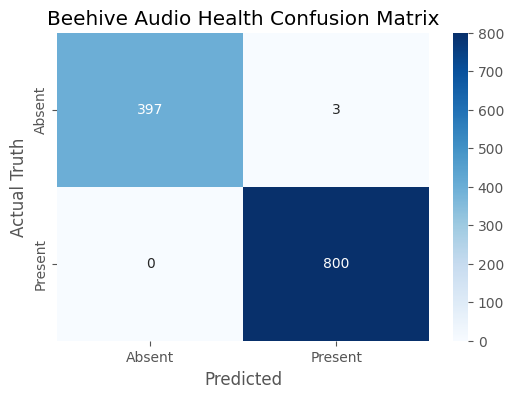

In [36]:
plt.figure(figsize=(6, 4))
cm = confusion_matrix(y_test, ypred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Absent', 'Present'], 
            yticklabels=['Absent', 'Present'])
plt.xlabel('Predicted')
plt.ylabel('Actual Truth')
plt.title('Beehive Audio Health Confusion Matrix')
plt.show()

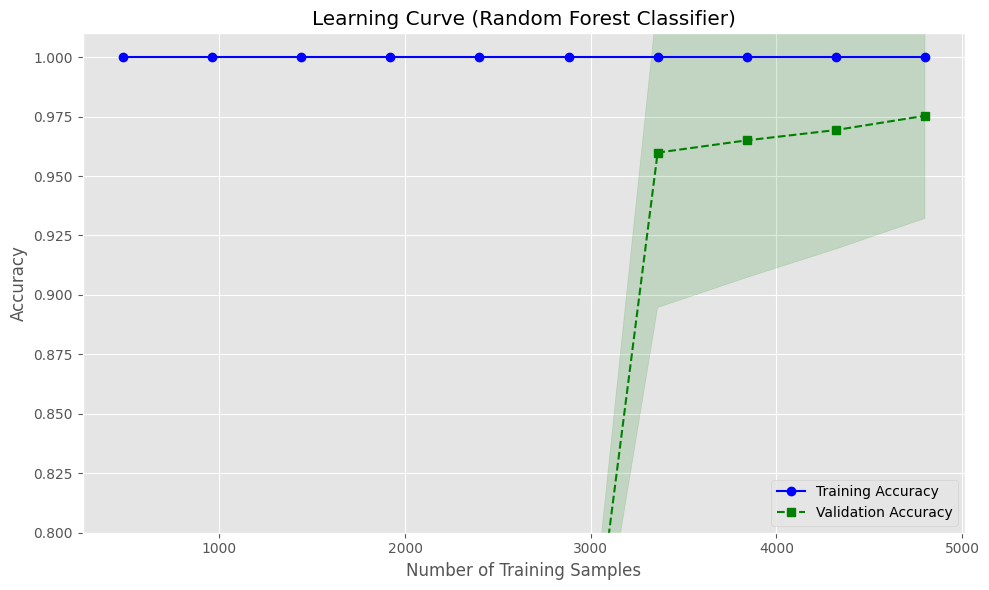

In [37]:
from sklearn.model_selection import learning_curve
train_sizes, train_scores, test_scores = learning_curve(
    estimator=RandomForestClassifier(n_estimators=100, random_state=42),
    X=X,
    y=y,
    cv=5,
    scoring='accuracy',
    train_sizes=np.linspace(0.1, 1.0, 10),
    n_jobs=-1
)

# Calculate mean and standard deviation for train and test sets
train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
test_std = np.std(test_scores, axis=1)

# Plot Learning Curve
plt.figure(figsize=(10, 6))

plt.plot(train_sizes, train_mean, color='blue', marker='o', label='Training Accuracy')
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15, color='blue')

plt.plot(train_sizes, test_mean, color='green', marker='s', linestyle='--', label='Validation Accuracy')
plt.fill_between(train_sizes, test_mean - test_std, test_mean + test_std, alpha=0.15, color='green')

plt.title('Learning Curve (Random Forest Classifier)')
plt.xlabel('Number of Training Samples')
plt.ylabel('Accuracy')
plt.ylim(0.8, 1.01)
plt.legend(loc='lower right')
plt.grid(True)
plt.tight_layout()
plt.show()

In [38]:
# saving the model 

import joblib 
import os 

os.makedirs('../models', exist_ok =True)

In [39]:
joblib.dump(model,'../models/hive_model.pkl')
print(f'model saved in /models/hive_model.pkl')

model saved in /models/hive_model.pkl
